<a href="https://colab.research.google.com/github/amicable594-beep/garbage-classification/blob/main/garbage_classification_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 제1회 빅데이터 프로그래밍 해커톤

# CNN을 활용한 쓰레기 이미지 분류

## 1. 프로젝트 개요

### 1.1 프로젝트 주제

본 프로젝트는 딥러닝의 합성곱 신경망(CNN, Convolutional Neural Network)을 활용하여 쓰레기 이미지를 자동으로 분류하는 모델을 구현하는 것을 목적으로 한다.

### 1.2 프로젝트 목적

일상생활에서 발생하는 쓰레기는 재질과 종류에 따라 분리배출 방법이 다르다. 하지만 종류가 다양하고 외형이 유사한 쓰레기가 존재하기 때문에 정확한 분류가 어려울 수 있다.

이에 따라 이미지 데이터를 학습한 CNN 모델을 이용하여 쓰레기 이미지를 자동으로 분류하고, 모델의 정확도와 분류 성능을 평가하고자 한다.

### 1.3 사용 데이터셋

- 데이터셋: Garbage Classification (12 classes)
- 출처: Kaggle
- 제공자: Mostafa Mohamed
- 데이터 주소: https://www.kaggle.com/datasets/mostafaabla/garbage-classification

### 1.4 분류 대상

본 프로젝트에서는 다음 12개 종류의 쓰레기를 분류한다.

1. Battery
2. Biological
3. Brown-glass
4. Cardboard
5. Clothes
6. Green-glass
7. Metal
8. Paper
9. Plastic
10. Shoes
11. Trash
12. White-glass

### 1.5 개발 방향

PyTorch를 활용하여 CNN 모델을 직접 구현한다.

학습 과정에서 데이터 증강, 과적합 분석 및 하이퍼파라미터 튜닝을 진행하고, 혼동행렬을 통해 클래스별 분류 성능을 평가한다.



### 생성형 AI 활용 기록 1

**활용 도구:** ChatGPT

**사용 목적:** CNN 모델의 개념 이해 및 프로젝트 구현 방향 설정

**실제 입력 프롬프트:**
- "cnn모델이 뭐야"
- "그걸 파이선으로 만들 수 있어?"
- "과적합은 뭐야?"
- "너가 만들어준 cnn모델의 적합도는 좋은편이야?"

**활용 내용:**

CNN의 기본 개념과 이미지 분류에서의 역할을 이해하고, PyTorch를 활용한 직접적인 모델 구현 방향을 설정하는 데 활용하였다.

In [2]:

# 필요한 라이브러리 불러오기

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# GPU 사용 여부 확인
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())
print("현재 사용 장치:", device)

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))


PyTorch 버전: 2.14.1+cu130
GPU 사용 가능: True
현재 사용 장치: cuda
GPU 이름: Tesla T4



### 2. 개발 환경 및 라이브러리

본 프로젝트는 Google Colab 환경에서 진행하였으며, 딥러닝 모델 구현을 위해 PyTorch를 사용하였다.

이미지 처리에는 PIL과 torchvision을 활용하였고, 데이터 분할 및 분류 성능 평가에는 Scikit-learn을 사용하였다.

모델 학습에는 GPU 가속을 활용하여 연산 효율성을 높이고자 하였다.


## 3. 데이터 수집 및 탐색

### 3.1 데이터셋 다운로드

Kaggle에서 제공하는 Garbage Classification 데이터셋을 사용하였다.

Kaggle API를 이용하여 데이터를 Google Colab 환경으로 다운로드하고, 압축을 해제하여 이미지 분류에 활용하였다.

In [3]:

!pip install -q kaggle


In [4]:

from google.colab import files

uploaded = files.upload()

import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod(
    "/root/.kaggle/kaggle.json",
    0o600
)

print("Kaggle 인증 파일 설정 완료")


Saving kaggle.json to kaggle.json
Kaggle 인증 파일 설정 완료


In [5]:

# 데이터 저장 경로 설정
DATA_ROOT = "/content/garbage_data"

os.makedirs(DATA_ROOT, exist_ok=True)

# Kaggle 데이터셋 다운로드
!kaggle datasets download -d mostafaabla/garbage-classification -p /content/garbage_data

# 압축 해제
!unzip -q -o /content/garbage_data/garbage-classification.zip -d /content/garbage_data

print("데이터셋 다운로드 및 압축 해제 완료")


Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
100% 239M/239M [00:02<00:00, 91.8MB/s]

데이터셋 다운로드 및 압축 해제 완료



### 3.2 데이터셋 구성 확인

다운로드한 데이터셋의 폴더 구조와 클래스별 이미지 수를 확인한다.

이를 통해 데이터가 정상적으로 수집되었는지 확인하고, 이후 학습에 사용할 이미지 경로와 라벨을 구성한다.

In [6]:

# 12개 클래스 정의

CLASS_NAMES = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

# 실제 클래스 폴더 위치 찾기
class_root = None

for root, dirs, files in os.walk(DATA_ROOT):
    if all(name in dirs for name in CLASS_NAMES):
        class_root = root
        break

if class_root is None:
    raise FileNotFoundError(
        "12개 클래스 폴더를 찾을 수 없습니다."
    )

print("이미지 폴더 위치:", class_root)

# 클래스별 이미지 개수 확인
class_counts = {}

for class_name in CLASS_NAMES:
    folder = os.path.join(class_root, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    class_counts[class_name] = len(image_files)

# 표로 출력
count_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
})

display(count_df)

print("전체 이미지 수:", sum(class_counts.values()))


이미지 폴더 위치: /content/garbage_data/garbage_classification


,Class,Image Count
0,battery,945
1,biological,985
2,brown-glass,607
3,cardboard,891
4,clothes,5325
5,green-glass,629
6,metal,769
7,paper,1050
8,plastic,865
9,shoes,1977


전체 이미지 수: 15515


## 4. 데이터 전처리 및 데이터 분할

전체 이미지 데이터 15,515장을 학습 데이터, 검증 데이터, 테스트 데이터로 분할하였다.

- 학습 데이터(Train): 70%
- 검증 데이터(Validation): 15%
- 테스트 데이터(Test): 15%

데이터 분할 과정에서는 층화 추출(Stratified Sampling)을 적용하였다. 이를 통해 각 데이터에 포함된 클래스의 비율이 전체 데이터의 클래스 비율과 유사하게 유지되도록 하였다.

학습 데이터는 CNN 모델의 가중치를 학습하는 데 사용하고, 검증 데이터는 학습 과정에서 모델의 성능을 확인하는 데 사용한다. 테스트 데이터는 최종 모델의 성능을 평가하는 데 사용한다.

In [7]:
# 이미지 경로와 정답 레이블 수집
image_paths = []
image_labels = []

for label, class_name in enumerate(CLASS_NAMES):
    folder = os.path.join(class_root, class_name)

    for file_name in os.listdir(folder):
        if file_name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        ):
            image_paths.append(os.path.join(folder, file_name))
            image_labels.append(label)

# 리스트를 배열로 변환
image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

# 1차 분할: 학습 70%, 나머지 30%
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# 2차 분할: 나머지 30%를 검증 15%, 테스트 15%로 분할
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("학습 데이터:", len(train_paths))
print("검증 데이터:", len(val_paths))
print("테스트 데이터:", len(test_paths))
print("전체 데이터:", len(image_paths))

학습 데이터: 10860
검증 데이터: 2327
테스트 데이터: 2328
전체 데이터: 15515


## 5. 이미지 전처리 및 데이터 증강

CNN 모델에 입력하기 위해 모든 이미지의 크기를 128×128 픽셀로 통일하였다. 또한 이미지의 픽셀값을 정규화하여 학습이 안정적으로 진행되도록 하였다.

학습 데이터에는 데이터 증강(Data Augmentation)을 적용하였다.

- RandomHorizontalFlip: 이미지를 좌우로 뒤집는다.
- RandomRotation: 이미지를 최대 15도 회전시킨다.
- ColorJitter: 이미지의 밝기와 색상 등을 무작위로 변경한다.

데이터 증강은 학습 데이터에만 적용하였다. 검증 데이터와 테스트 데이터에는 동일한 평가가 가능하도록 이미지 크기 조정과 정규화만 적용하였다.

In [8]:
# 학습 데이터에 적용할 전처리 및 데이터 증강
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# 검증 및 테스트 데이터에 적용할 전처리
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("이미지 전처리 및 데이터 증강 설정 완료")

이미지 전처리 및 데이터 증강 설정 완료


### 5-1. PyTorch Dataset 및 DataLoader 생성

PyTorch의 Dataset 클래스를 활용하여 이미지 경로와 정답 레이블을 연결하였다.

DataLoader는 데이터를 일정한 크기의 배치(Batch)로 나누어 모델에 전달하는 역할을 한다. 이번 프로젝트에서는 배치 크기를 32로 설정하였다.

In [9]:
class GarbageDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = int(self.labels[idx])

        if self.transform:
            image = self.transform(image)

        return image, label


# Dataset 생성
train_dataset = GarbageDataset(
    train_paths, train_labels, train_transform
)

val_dataset = GarbageDataset(
    val_paths, val_labels, test_transform
)

test_dataset = GarbageDataset(
    test_paths, test_labels, test_transform
)

# DataLoader 생성
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("학습 데이터셋:", len(train_dataset))
print("검증 데이터셋:", len(val_dataset))
print("테스트 데이터셋:", len(test_dataset))
print("학습 배치 수:", len(train_loader))

학습 데이터셋: 10860
검증 데이터셋: 2327
테스트 데이터셋: 2328
학습 배치 수: 340


In [10]:
# 이전에 생성한 데이터셋과 DataLoader가 남아 있는지 확인
required_vars = [
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_loader",
    "val_loader",
    "test_loader"
]

for var in required_vars:
    print(var, ":", var in globals())

train_dataset : True
val_dataset : True
test_dataset : True
train_loader : True
val_loader : True
test_loader : True


### 5-2. 학습 이미지 시각화

CNN 모델을 학습하기 전에 데이터셋에서 이미지가 정상적으로 불러와지는지 확인하였다.

학습 데이터에서 일부 이미지를 추출하여 화면에 표시하고, 각 이미지의 실제 클래스 레이블을 함께 확인하였다.

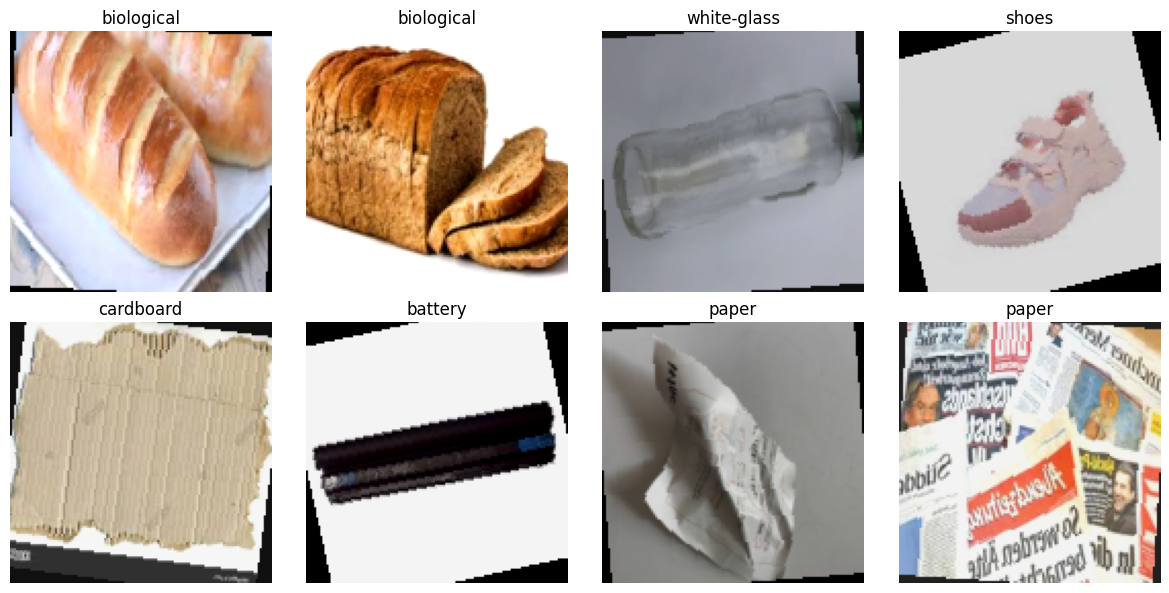

In [11]:
# 학습 데이터에서 이미지와 레이블 가져오기
images, labels = next(iter(train_loader))

# 이미지 8장 시각화
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    # 정규화된 이미지 복원
    image = images[i] * 0.5 + 0.5
    image = image.permute(1, 2, 0).numpy()

    plt.imshow(image)
    plt.title(CLASS_NAMES[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. CNN 모델 설계

본 프로젝트에서는 12가지 쓰레기 종류를 분류하기 위해 합성곱 신경망(CNN, Convolutional Neural Network)을 구현하였다.

CNN은 이미지의 특징을 자동으로 추출하는 데 효과적인 딥러닝 모델이다.

모델은 총 3개의 합성곱층으로 구성하였으며, 각 합성곱층 뒤에는 ReLU 활성화 함수와 최대 풀링층을 적용하였다.

또한 완전연결층에 Dropout을 적용하여 과적합을 방지하고자 하였다.

In [12]:
class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12):
        super(GarbageCNN, self).__init__()

        self.features = nn.Sequential(
            # 첫 번째 합성곱층
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 두 번째 합성곱층
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 세 번째 합성곱층
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# 모델 생성
model = GarbageCNN(num_classes=12).to(device)

# 손실 함수와 최적화 알고리즘
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

GarbageCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=12, bias=True)
  )
)


In [13]:
class GarbageCNN_NoDropout(nn.Module):
    def __init__(self, num_classes=12):
        super(GarbageCNN_NoDropout, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [14]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("학습 가능한 파라미터 수:", f"{total_params:,}")
print("사용 장치:", device)

학습 가능한 파라미터 수: 8,485,196
사용 장치: cuda


In [15]:
# 7. 최종 CNN 모델 학습

import copy

# 재현성을 위한 난수 고정
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 최종 모델 생성
final_model = GarbageCNN(num_classes=12).to(device)

# 손실함수 및 최적화 알고리즘
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.0005
)

# 학습 설정
epochs = 20
best_val_acc = 0
best_model_state = None

# 학습 기록
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

# 모델 학습
for epoch in range(epochs):

    # 학습 단계
    final_model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = final_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    # 검증 단계
    final_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = final_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    # 평균 계산
    train_loss /= train_total
    val_loss /= val_total

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    # 학습 기록 저장
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # 검증 정확도가 가장 높은 모델 저장
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_model_state = {
            k: v.detach().cpu().clone()
            for k, v in final_model.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

# 가장 성능이 좋았던 모델 복원
final_model.load_state_dict(best_model_state)

# 최종 모델 가중치 저장
torch.save(
    final_model.state_dict(),
    "/content/garbage_cnn_final.pth"
)

print("\n최종 모델 학습 완료!")
print(f"최고 검증 정확도: {best_val_acc * 100:.2f}%")
print("모델 저장 완료!")

Epoch [1/20] Train Loss: 1.5309 Train Acc: 0.4982 Val Loss: 1.1332 Val Acc: 0.6218
Epoch [2/20] Train Loss: 1.1888 Train Acc: 0.6012 Val Loss: 1.0068 Val Acc: 0.6575
Epoch [3/20] Train Loss: 1.0543 Train Acc: 0.6505 Val Loss: 0.9421 Val Acc: 0.6794
Epoch [4/20] Train Loss: 0.9599 Train Acc: 0.6835 Val Loss: 0.8548 Val Acc: 0.7190
Epoch [5/20] Train Loss: 0.8916 Train Acc: 0.7092 Val Loss: 0.7796 Val Acc: 0.7387
Epoch [6/20] Train Loss: 0.8331 Train Acc: 0.7251 Val Loss: 0.7712 Val Acc: 0.7533
Epoch [7/20] Train Loss: 0.7769 Train Acc: 0.7434 Val Loss: 0.7505 Val Acc: 0.7735
Epoch [8/20] Train Loss: 0.7428 Train Acc: 0.7547 Val Loss: 0.6843 Val Acc: 0.7787
Epoch [9/20] Train Loss: 0.6894 Train Acc: 0.7715 Val Loss: 0.7040 Val Acc: 0.7701
Epoch [10/20] Train Loss: 0.6478 Train Acc: 0.7828 Val Loss: 0.6638 Val Acc: 0.7929
Epoch [11/20] Train Loss: 0.6270 Train Acc: 0.7924 Val Loss: 0.6762 Val Acc: 0.7770
Epoch [12/20] Train Loss: 0.5996 Train Acc: 0.8041 Val Loss: 0.6457 Val Acc: 0.7933
E

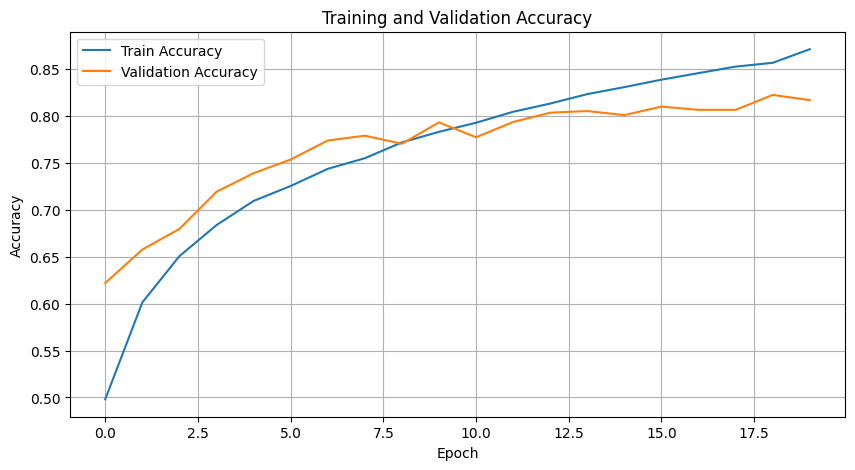

In [16]:
# 학습 및 검증 정확도 그래프

plt.figure(figsize=(10, 5))

plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

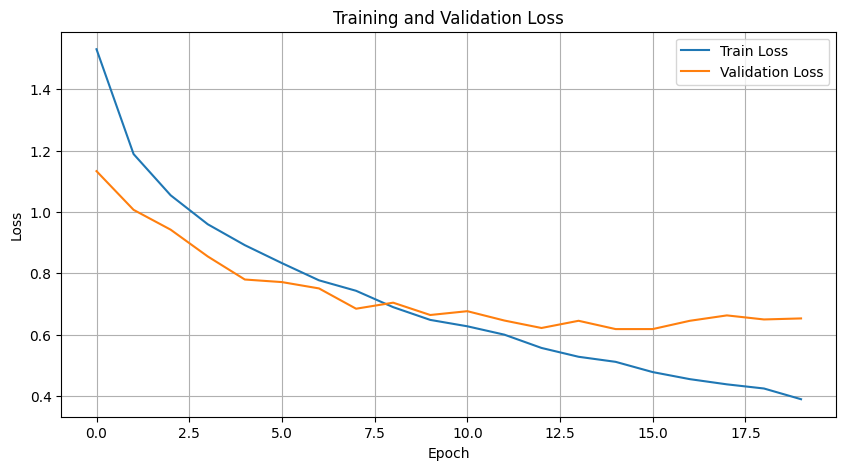

In [17]:
# 학습 및 검증 손실 그래프

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# 8. 최종 모델 테스트 평가

from sklearn.metrics import accuracy_score, classification_report

final_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# 테스트 정확도
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"최종 테스트 정확도: {test_accuracy * 100:.2f}%")

# 클래스별 성능 평가
print("\n[클래스별 분류 성능]")
print(classification_report(
    all_labels,
    all_predictions,
  target_names=CLASS_NAMES,
    digits=4
))

최종 테스트 정확도: 82.35%

[클래스별 분류 성능]
              precision    recall  f1-score   support

     battery     0.7365    0.7676    0.7517       142
  biological     0.7305    0.8243    0.7746       148
 brown-glass     0.7717    0.7802    0.7760        91
   cardboard     0.8547    0.7463    0.7968       134
     clothes     0.9167    0.9499    0.9330       799
 green-glass     0.8764    0.8298    0.8525        94
       metal     0.6442    0.5826    0.6119       115
       paper     0.8841    0.7722    0.8243       158
     plastic     0.6644    0.7615    0.7097       130
       shoes     0.7860    0.7912    0.7886       297
       trash     0.7921    0.7692    0.7805       104
 white-glass     0.7812    0.6466    0.7075       116

    accuracy                         0.8235      2328
   macro avg     0.7865    0.7685    0.7756      2328
weighted avg     0.8242    0.8235    0.8225      2328

